# Customer Sales Exploratory Data Analysis (EDA)

**Python · Pandas · NumPy · Matplotlib · Seaborn**

## Project overview
This notebook explores a customer sales dataset to understand purchasing patterns across **gender, age group, state, occupation, product category, and marital status**. The workflow follows the original class project: inspect the data, clean it, calculate grouped totals, and create charts.

**Learning approach:** Some chart types are deliberately repeated. They document my progression from a simple chart to a combined or more clearly formatted chart; the repeated examples are labelled as practice stages rather than separate discoveries.

**Data note:** The project uses a customer sales dataset containing 11,251 rows and 15 columns before cleaning. The dataset was successfully loaded, cleaned, and analyzed using Python, Pandas, NumPy, Matplotlib, and Seaborn. Customer names and IDs have been excluded from displayed previews in this public-facing version.

**How to run:** Put an appropriately shareable `sales_data (4).csv` in the same working folder as this notebook, or set `csv_path` to its location. Run the cells from top to bottom. If the original dataset cannot be redistributed, provide a permitted equivalent and explain any resulting differences in the README.

**Dataset verification:** The original dataset contains 11,251 rows and 15 columns. During data cleaning, 12 rows with missing `Amount` values and 8 exact duplicate rows were removed. Two entirely empty columns (`Status` and `unnamed1`) were also dropped, leaving 11,231 rows and 13 columns for analysis. The complete notebook was successfully executed and the visualizations and findings were verified.

**Data sharing note:** The original dataset was provided for educational purposes. Its redistribution permission has not been independently confirmed, so the source CSV should not be published publicly without appropriate authorization.

## 1. Import libraries

- **Pandas (`pd`)** loads, cleans, and groups tabular data.
- **NumPy (`np`)** supports numerical calculations (imported as in the original project).
- **Matplotlib (`plt`)** controls plots, figure sizes, titles, and pie charts.
- **Seaborn (`sns`)** makes categorical plots such as count plots and bar plots.

*Expected result:* Imports run without errors. No output is required.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load the dataset

The original notebook loaded a CSV using a personal Windows path. This version uses a **relative filename**, so it can run from a cloned GitHub repository when the CSV is placed in the notebook's working directory. The original file used `latin1`; that setting is retained to match the source project.

**Privacy:** Preview only non-identifying columns here. The raw file contains `Cust_name` and `User_ID`, so avoid publishing raw row previews or saved notebook outputs showing those fields.

In [2]:
from pathlib import Path

csv_path = Path("sales_data (4).csv")
if not csv_path.exists():
    raise FileNotFoundError(
        "Place 'sales_data (4).csv' in the notebook working directory "
        "or change csv_path to the correct location before running."
    )

df = pd.read_csv(csv_path, encoding='latin1')
preview_cols = ['Gender', 'Age Group', 'State', 'Zone', 'Occupation', 'Product_Category', 'Orders', 'Amount']
df[[col for col in preview_cols if col in df.columns]].head()

,Gender,Age Group,State,Zone,Occupation,Product_Category,Orders,Amount
0,F,26-35,Maharashtra,Western,Healthcare,Auto,1,23952.0
1,F,26-35,Andhra Pradesh,Southern,Govt,Auto,3,23934.0
2,F,26-35,Uttar Pradesh,Central,Automobile,Auto,3,23924.0
3,M,0-17,Karnataka,Southern,Construction,Auto,2,23912.0
4,M,26-35,Gujarat,Western,Food Processing,Auto,2,23877.0


## 3. Inspect dataset shape

`df.shape` returns `(number_of_rows, number_of_columns)`. In the original notebook, this was **(11251, 15)**. The values shown below come from whichever CSV you actually load.

In [3]:
# checking the no. of rows and columns.
df.shape

(11251, 15)

## 4. Check missing values

`df.isna().sum()` counts missing entries in each column. In the original results, `Amount` had **12** missing values and `Status` and `unnamed1` were completely empty (**11,251** missing each). These counts are descriptive of the original notebook, not a guarantee about another dataset.

In [4]:
# checking the null values present in each column
df.isna().sum()

User_ID                 0
Cust_name               0
Product_ID              0
Gender                  0
Age Group               0
Age                     0
Marital_Status          0
State                   0
Zone                    0
Occupation              0
Product_Category        0
Orders                  0
Amount                 12
Status              11251
unnamed1            11251
dtype: int64

## 5. Drop fully empty columns

`Status` and `unnamed1` contained no useful values in the original data, so the project removed them with `drop(..., axis=1, inplace=True)`. Here `errors='ignore'` makes the cell safe if those columns were already removed in a permitted alternative CSV.

In [5]:
# Drop the two fully empty columns (same approach as the original)
df.drop(['Status', 'unnamed1'], axis=1, inplace=True, errors='ignore')

### Inspect the remaining columns (privacy-safe)

The original project displayed the whole DataFrame here. For public sharing, this version displays only the column names and a small non-identifying preview, not customer names or IDs.

In [6]:
print('Columns remaining:', df.columns.tolist())
df[[col for col in preview_cols if col in df.columns]].head()

Columns remaining: ['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age', 'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category', 'Orders', 'Amount']


,Gender,Age Group,State,Zone,Occupation,Product_Category,Orders,Amount
0,F,26-35,Maharashtra,Western,Healthcare,Auto,1,23952.0
1,F,26-35,Andhra Pradesh,Southern,Govt,Auto,3,23934.0
2,F,26-35,Uttar Pradesh,Central,Automobile,Auto,3,23924.0
3,M,0-17,Karnataka,Southern,Construction,Auto,2,23912.0
4,M,26-35,Gujarat,Western,Food Processing,Auto,2,23877.0


### Recheck missing values after removing columns

This repeats the missing-value check intentionally: it shows that the two empty columns have disappeared, while missing `Amount` values still need attention.

In [7]:
#  Again checking the null values present in each column
df.isna().sum()

User_ID              0
Cust_name            0
Product_ID           0
Gender               0
Age Group            0
Age                  0
Marital_Status       0
State                0
Zone                 0
Occupation           0
Product_Category     0
Orders               0
Amount              12
dtype: int64

## 6. Handle missing sales amounts

The original notebook **identified** 12 missing `Amount` entries but did not explicitly treat them. Here we exclude records with no amount from spending analysis rather than inventing an amount. This changes the row count, so compare before/after counts.

**Interpretation:** Totals reflect transactions with a recorded amount only; rows with missing amounts are excluded.

In [8]:
print('Rows before Amount cleaning:', len(df))
print('Missing Amount values:', df['Amount'].isna().sum())
df.dropna(subset=['Amount'], inplace=True)
print('Rows after Amount cleaning:', len(df))

Rows before Amount cleaning: 11251
Missing Amount values: 12
Rows after Amount cleaning: 11239


## 7. Convert category codes to readable labels

In the source data, `Gender` used `M` and `F`. The original code mapped these to `Male` and `Female`. `Marital_Status` used `0` and `1`, mapped to `single` and `Married`. We retain the same `map()` approach, but display only the changed columns.

**Tip:** `map()` replaces each value according to the dictionary. Unexpected codes would become missing values, so inspect unique values if your dataset differs.

In [9]:
# Convert M/F to readable categories
df['Gender'] = df['Gender'].map({'M':'Male', 'F':'Female'})
df[['Gender', 'Age Group', 'State']].head()

,Gender,Age Group,State
0,Female,26-35,Maharashtra
1,Female,26-35,Andhra Pradesh
2,Female,26-35,Uttar Pradesh
3,Male,0-17,Karnataka
4,Male,26-35,Gujarat


In [10]:
# Convert 0/1 to marital-status labels
df['Marital_Status'] = df['Marital_Status'].map({0:'single', 1:'Married'})
df[['Marital_Status', 'Gender', 'Age Group']].head()

,Marital_Status,Gender,Age Group
0,single,Female,26-35
1,Married,Female,26-35
2,Married,Female,26-35
3,single,Male,0-17
4,Married,Male,26-35


## 8. Explore unique states

`unique()` returns distinct values from the `State` column. It is useful for detecting inconsistent spellings or encoding problems (for example, two versions of the same state name). This cell is intentionally retained from the original workflow.

**Verified CSV detail:** The state `Andhra Pradesh` contains a non-breaking space (`\u00a0`) in the source file. The next cell standardizes whitespace in state names before grouping. This does not change the meaning of the data.

In [11]:
# Find out the Unique values.
df['State'].unique()

<StringArray>
[     'Maharashtra',   'Andhra Pradesh',    'Uttar Pradesh',
        'Karnataka',          'Gujarat', 'Himachal Pradesh',
            'Delhi',        'Jharkhand',           'Kerala',
          'Haryana',   'Madhya Pradesh',            'Bihar',
        'Rajasthan',      'Uttarakhand',        'Telangana',
           'Punjab']
Length: 16, dtype: str

In [12]:
# Standardize unusual whitespace in state names (e.g. Andhra\u00a0Pradesh)
df['State'] = df['State'].str.replace('\u00a0', ' ', regex=False).str.strip()
print('State labels standardized.')

State labels standardized.


## 9. Check and remove exact duplicate rows

The original project used `duplicated().sum()` followed by `drop_duplicates(inplace=True)`. In a notebook, the first expression was not displayed because another statement followed it. Here we **print** the count before removal.

**Caution:** This checks entire-row duplicates, not repeated customers or repeated product purchases. A customer can legitimately appear in multiple transactions.

In [13]:
# Count duplicates before removing them
print('Exact duplicate rows:', df.duplicated().sum())
df.drop_duplicates(inplace=True)
print('Rows after removing exact duplicates:', len(df))

Exact duplicate rows: 8
Rows after removing exact duplicates: 11231


## 10. Data visualization

We now answer business questions using categorical counts and **total recorded spending** (`Amount`).

- **Count plot:** How many rows belong to each category?
- **GroupBy + sum:** How much total amount is associated with each category?
- **Bar plot:** Compare aggregated totals across categories.
- **Pie chart:** Show category shares of a total.

These describe the available records; they do not prove that a demographic group spends more per person or that the pattern applies to the wider population.

### Helper function: label bars

The `label()` function loops through bar containers and places values above bars. It is used in the gender count plots.

In [14]:
def label(a):
    for i in a.containers:
        a.bar_label(i)

## 11. Gender analysis — practice stage 1: count plot

**Question:** How many dataset rows are labelled Male and Female?

`countplot()` counts rows in each gender category. The original custom colors are retained. A larger count means **more rows**, not necessarily greater spending.

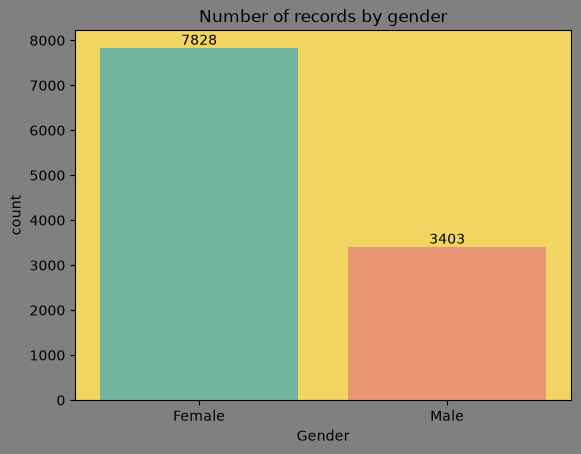

In [15]:
plt.figure(facecolor='grey')
c_g=sns.countplot(x='Gender',data=df,hue='Gender',palette='Set2')
plt.gca().set_facecolor('#F1D562')
label(c_g)
plt.title('Number of records by gender')
plt.show()

### Gender analysis — practice stage 2: spending pie chart

The original code uses `groupby('Gender')['Amount'].sum()` to calculate the **total recorded amount** for each gender, then uses `plt.pie()` to show shares. This is different from the count plot above.

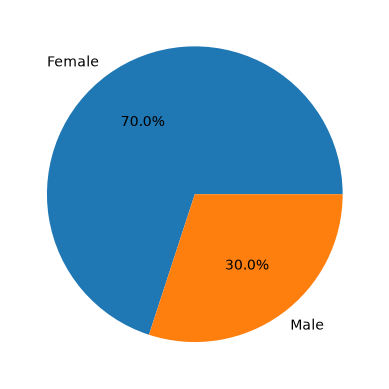

In [16]:
g_g=df.groupby('Gender')['Amount'].sum()
g_g=pd.DataFrame(g_g)
plt.pie(g_g['Amount'],labels=g_g.index,autopct='%0.1f%%')
plt.show()

### Gender analysis — practice stage 3: combine the charts

This version introduces `plt.subplots()` and uses `axes[0]` for counts and `axes[1]` for spending shares. The code is kept as a learning step before the more polished version.

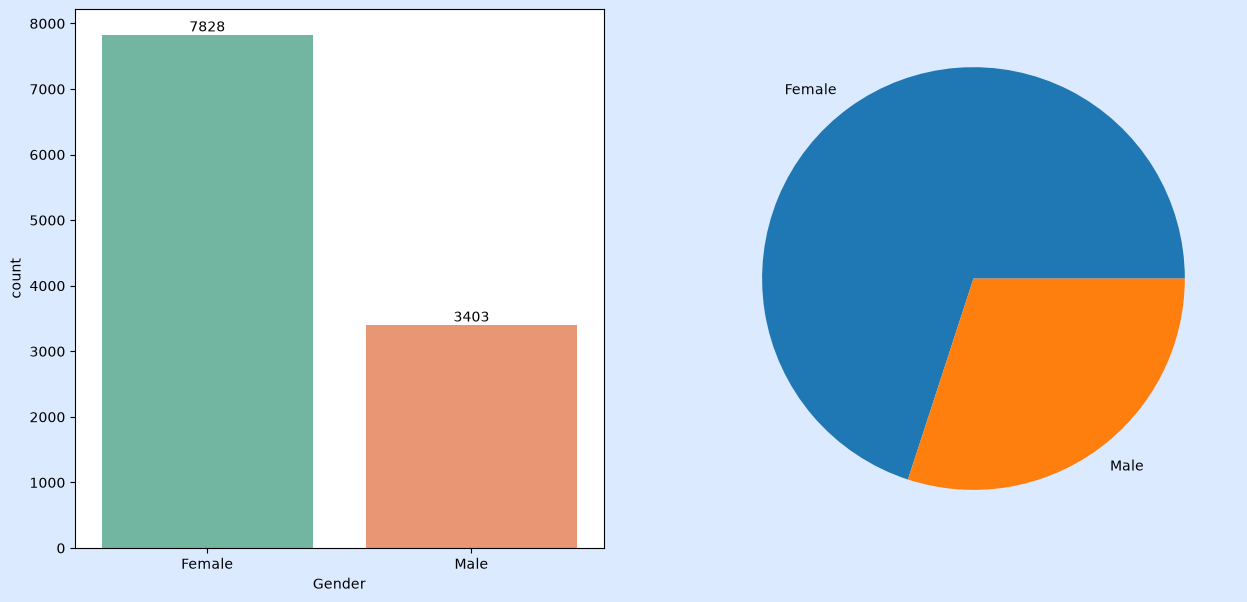

In [17]:
fig,axes=plt.subplots(nrows=1,ncols=2,facecolor='#DBEAFE',figsize=(15,7))
c_g=sns.countplot(x='Gender',data=df,hue='Gender',palette='Set2',ax=axes[0])
label(c_g)

#########################################################################
g_g=df.groupby('Gender')['Amount'].sum()
g_g=pd.DataFrame(g_g)
axes[1].pie(g_g['Amount'],labels=g_g.index)
plt.show()

### Gender analysis — practice stage 4: add axis and percentage labels

This stage demonstrates font sizes, axis labels, pie colors, and percentages. `as_index=False` keeps the grouping column as a regular DataFrame column; no extra `reset_index()` is required.

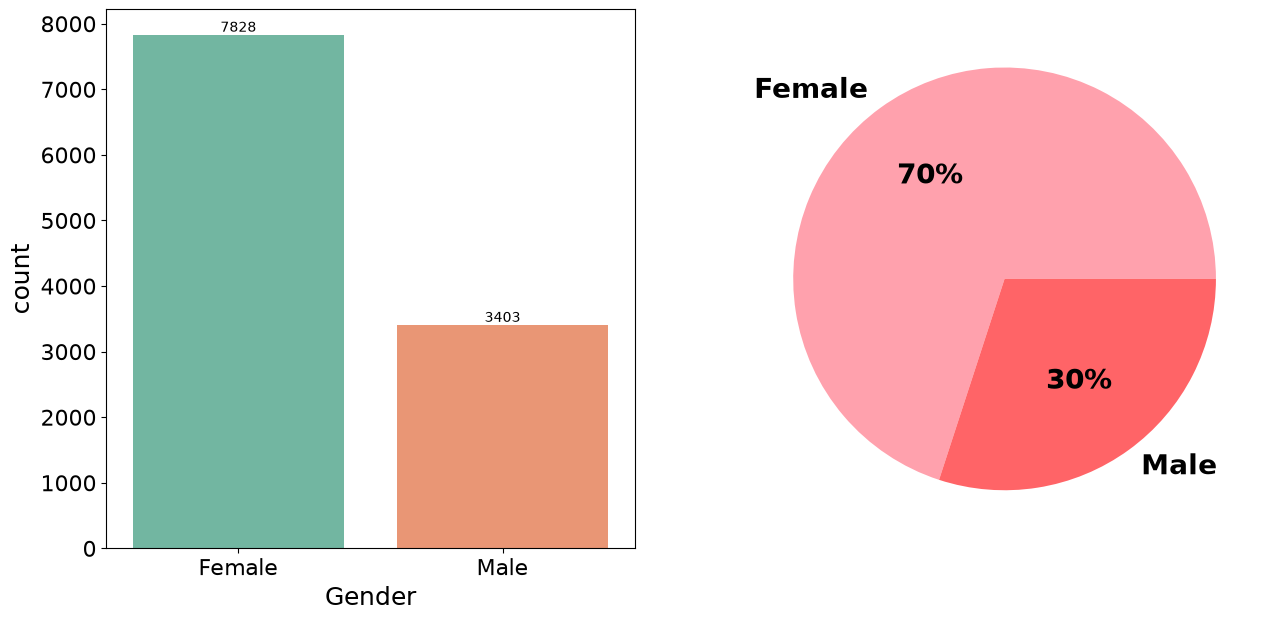

In [18]:
fig,axes=plt.subplots(nrows=1,ncols=2,figsize=(15,7))
c_g=sns.countplot(x='Gender',data=df,hue='Gender',palette='Set2',ax=axes[0])
label(c_g)
axes[0].tick_params(axis='both',labelsize=16)
axes[0].set_xlabel('Gender',fontsize=18)
axes[0].set_ylabel('count',fontsize=18)
gr_g=df.groupby('Gender',as_index=False)['Amount'].sum() # level swap ho sakta hai usse bachne ke liye as_index use kiya hai.
axes[1].pie(gr_g['Amount'],labels=gr_g['Gender'],autopct='%0.0f%%'
            ,colors=['#FFA1AD','#FF6467'],textprops={'fontsize':20, 'weight':'bold'})
plt.show()

### Gender analysis — final combined visualization

This is the most presentation-ready gender chart in the original notebook. It places counts and total spending shares side by side and uses a custom background and text styling. The earlier charts are intentionally retained as practice iterations.

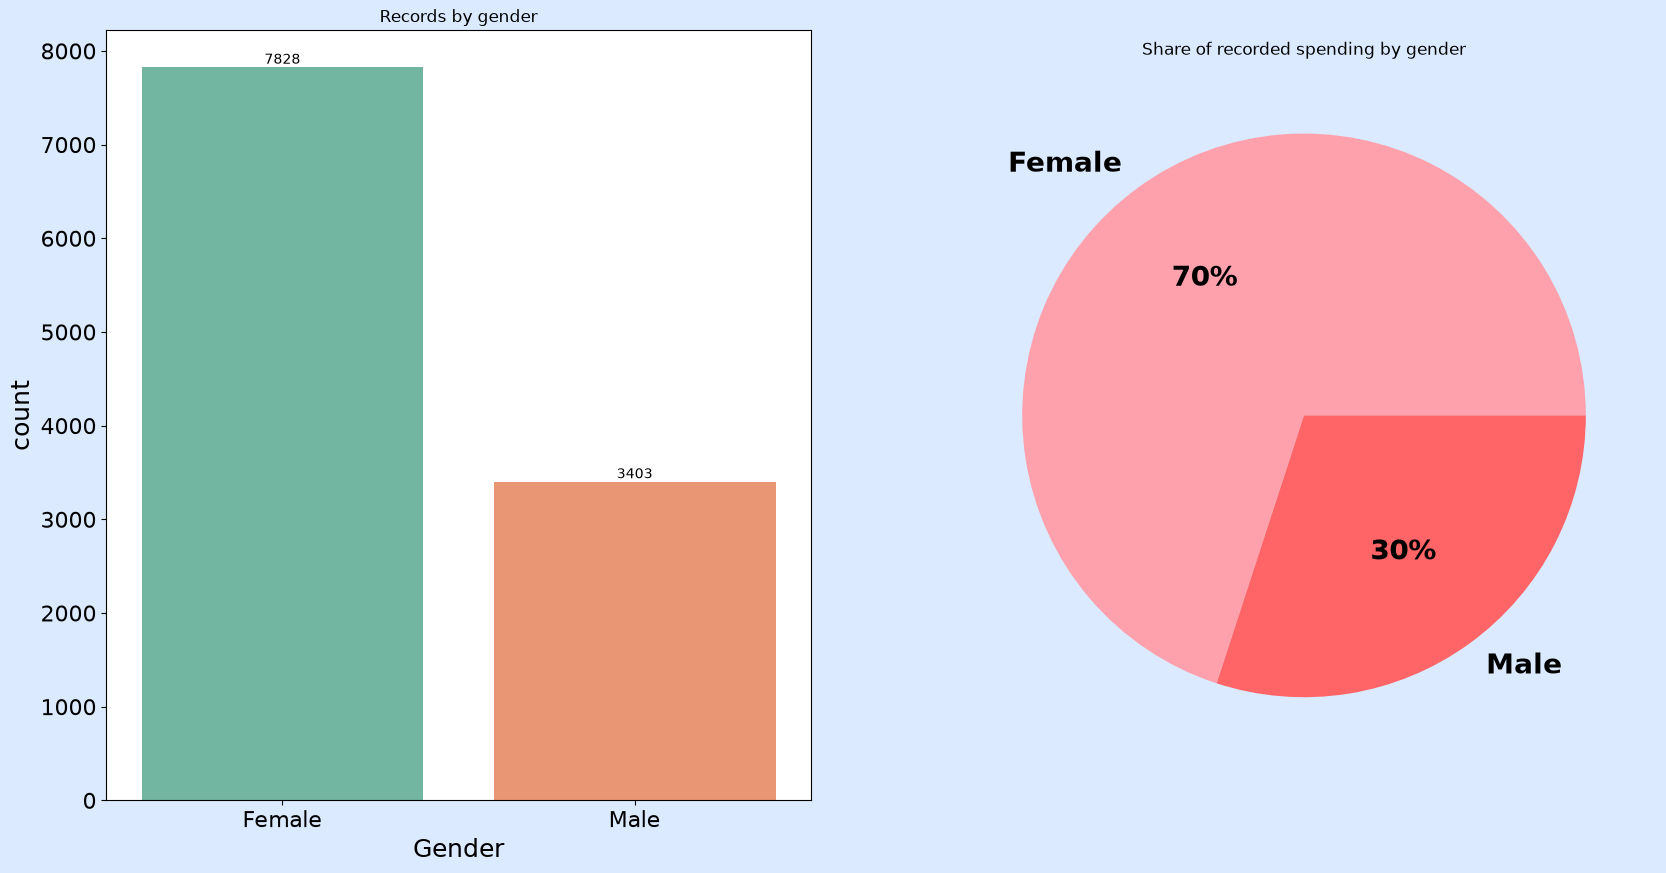

In [19]:
fig,axes=plt.subplots(nrows=1,ncols=2,facecolor='#DBEAFE',figsize=(20,10))
c_g=sns.countplot(x='Gender',data=df,hue='Gender',palette='Set2',ax=axes[0])
label(c_g)
axes[0].tick_params(axis='both',labelsize=16)
axes[0].set_xlabel('Gender',fontsize=18)
axes[0].set_ylabel('count',fontsize=18)
gr_g=df.groupby('Gender',as_index=False)['Amount'].sum() # level swap ho sakta hai usse bachne ke liye as_index use kiya hai.
axes[1].pie(gr_g['Amount'],labels=gr_g['Gender'],autopct='%0.0f%%'
            ,colors=['#FFA1AD','#FF6467'],textprops={'fontsize':20, 'weight':'bold'})
axes[0].set_title('Records by gender')
axes[1].set_title('Share of recorded spending by gender')
plt.show()


**Original finding:** The notebook reported that **Female** customers accounted for the larger total recorded spending. **How to interpret:** Compare the pie-chart shares; this is an aggregate of recorded amounts, not average spending per customer. Rerun with the cleaned data to confirm the direction of the finding.

## 12. Age-group analysis

**Question:** Which age group contributes the largest total recorded amount?

`groupby('Age Group')['Amount'].sum()` sums spending within each age group. `sort_values(..., ascending=False)` orders groups from highest to lowest, and Seaborn's `barplot()` visualizes the totals.

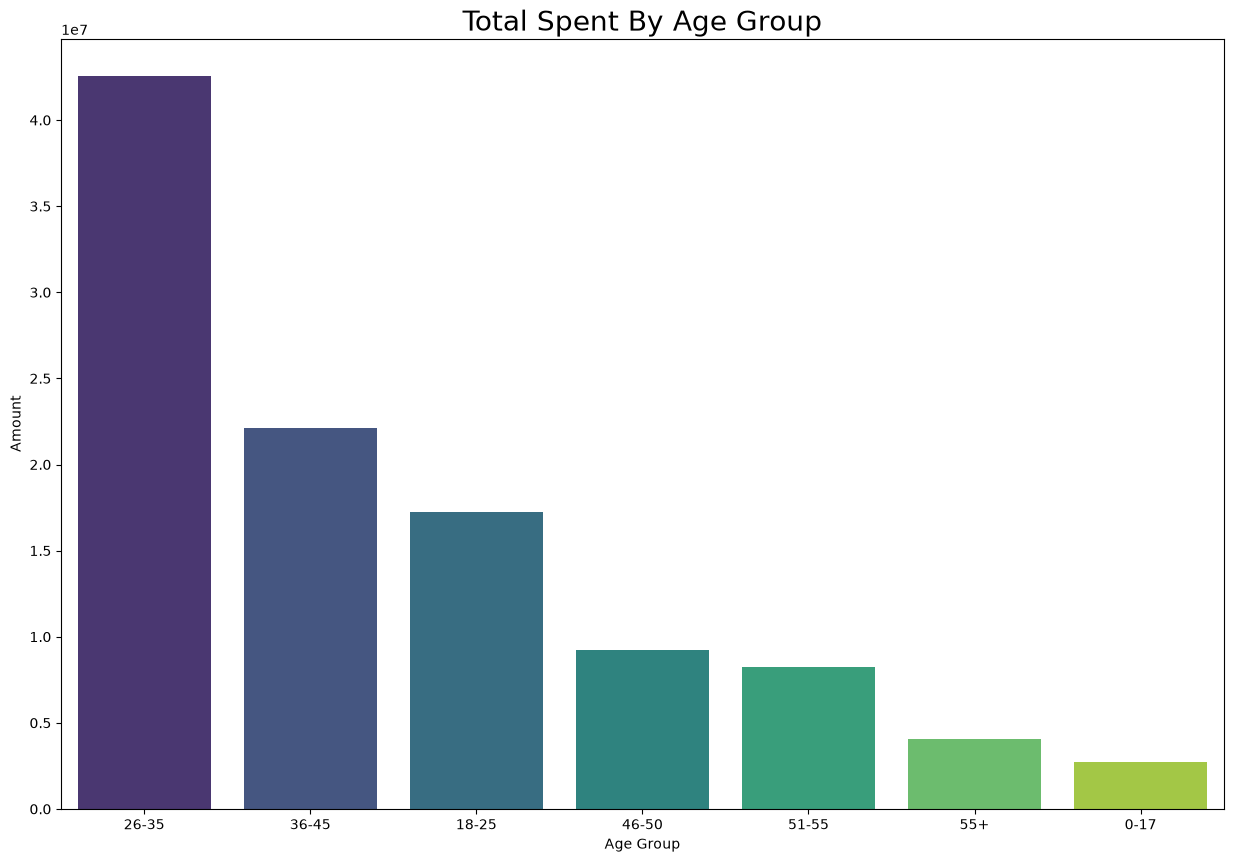

In [20]:
# age group analysis
fig,ax=plt.subplots(figsize=(15,10))
sales_age=df.groupby('Age Group',as_index=False)['Amount'].sum().sort_values(
    by='Amount',ascending=False)
sns.barplot(x='Age Group',y='Amount',data=sales_age,hue='Age Group',palette='viridis',ax=ax)
ax.set_title('Total Spent By Age Group',fontsize=20)
plt.show()

**Original finding:** The **26–35** age group had the highest total recorded amount in the original notebook. This is not an age-adjusted or per-customer average. Verify the ranking after rerunning the cleaned data.

## 13. State-wise analysis

**Question:** Which states contribute the highest total recorded sales?

`groupby('State')` aggregates spending by state; `.head(10)` selects the **top 10 states** after sorting. Rotating x-axis labels makes long state names easier to read.

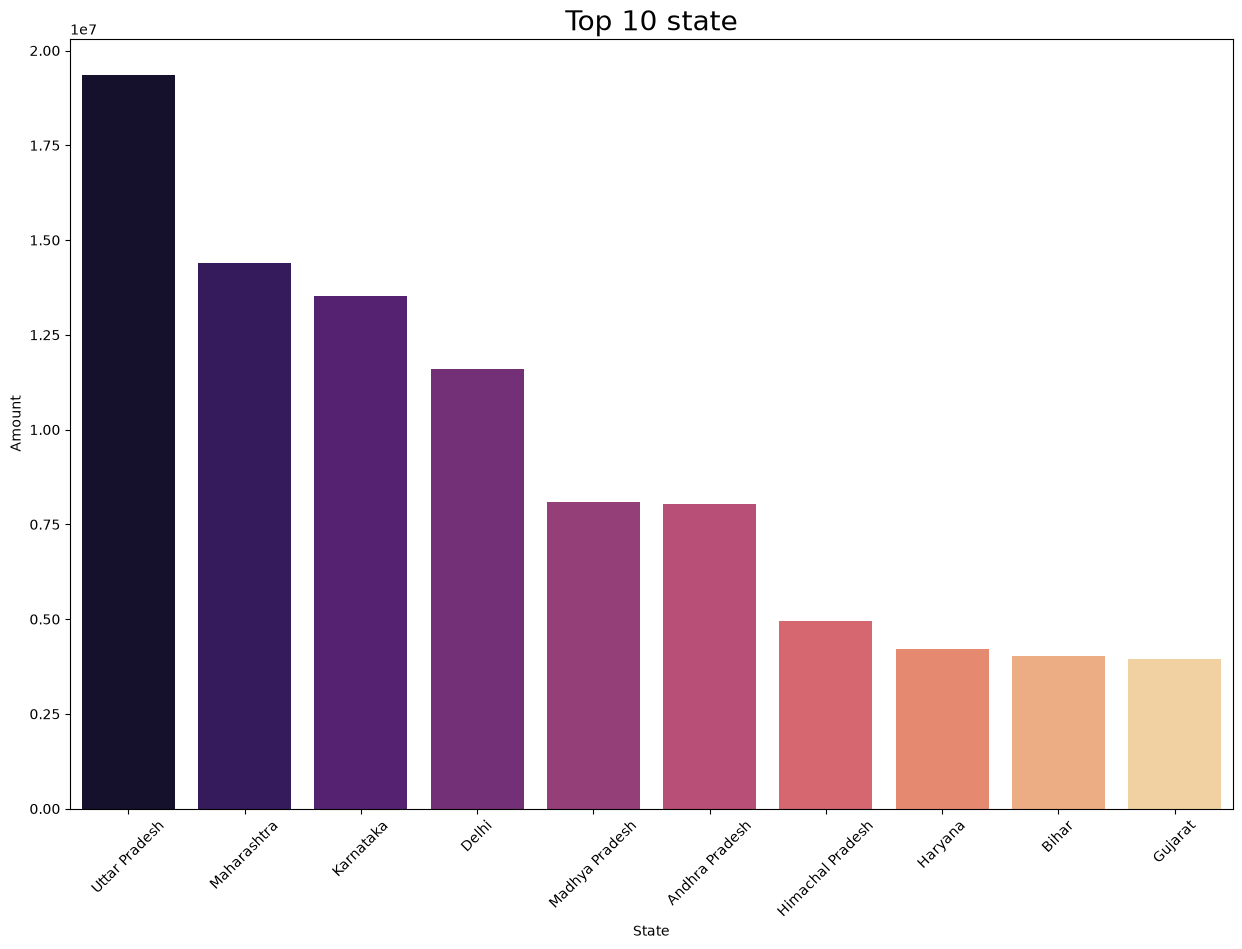

In [21]:
# State Wise analysis
fig,ax=plt.subplots(figsize=(15,10))
top_state=df.groupby('State',as_index=False)['Amount'].sum().sort_values(
    by='Amount',ascending=False).head(10)
sns.barplot(x='State',y='Amount',data=top_state,hue='State',palette='magma',ax=ax)
ax.set_title('Top 10 state',fontsize=20)
plt.xticks(rotation=45)
plt.show()



**Original finding:** **Uttar Pradesh** had the highest total recorded spending in the source analysis. This reflects the records in this dataset, not a claim about all retail sales in India.

## 14. Occupation-wise analysis

**Question:** Which occupation category has the largest total recorded spending?

The same `groupby` + `sum` + `sort_values` pattern is reused, this time on `Occupation`. This repetition is intentional: the same analysis method works on different categorical columns.

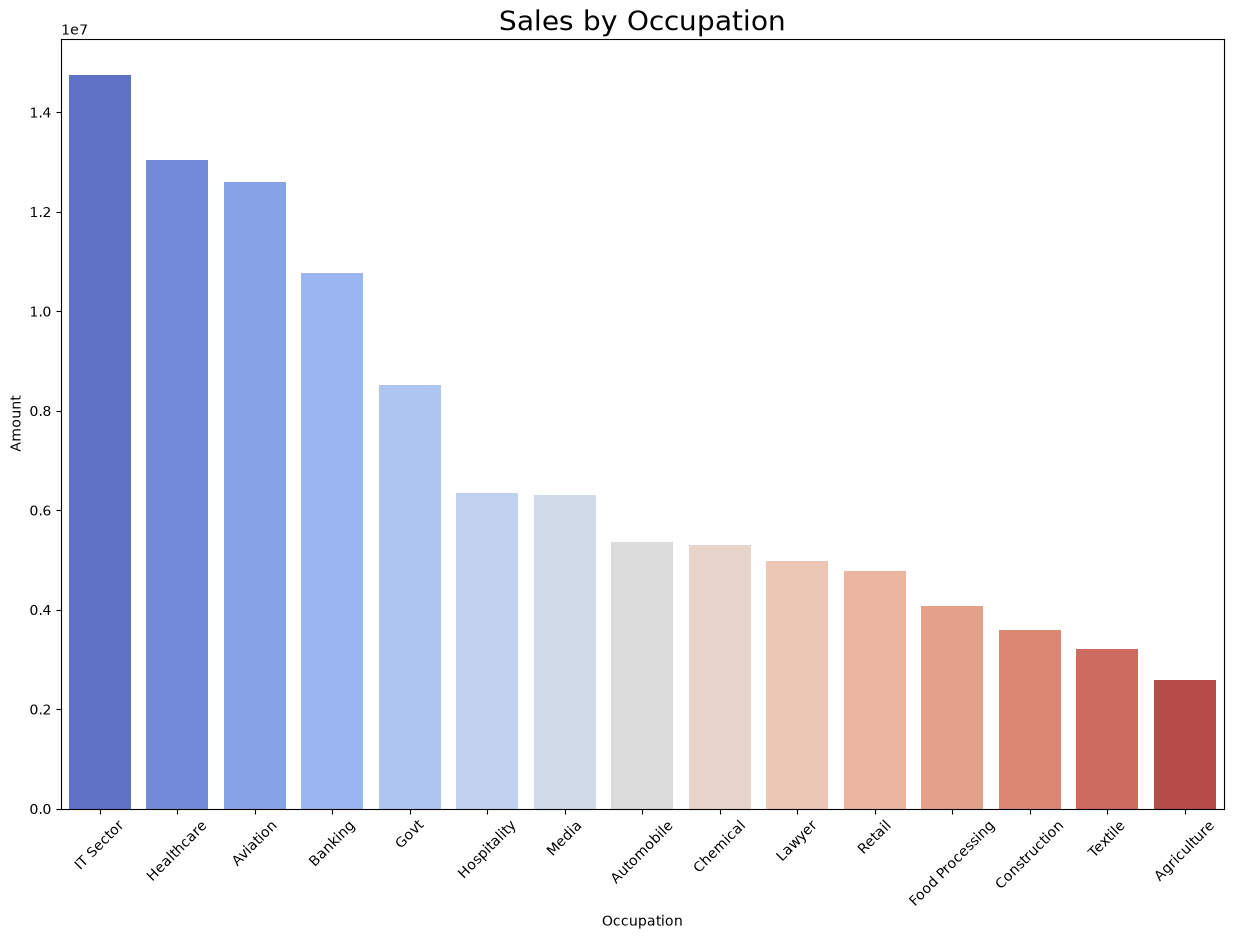

In [22]:
# Occupation wise analysis 
fig,ax=plt.subplots(figsize=(15,10))
sales_occ=df.groupby('Occupation',as_index=False)['Amount'].sum().sort_values(
    by='Amount',ascending=False)
sns.barplot(x='Occupation',y='Amount',data=sales_occ,hue='Occupation',palette='coolwarm',ax=ax)
ax.set_title('Sales by Occupation',fontsize=20)
plt.xticks(rotation=45)
plt.show()


**Original finding:** The **IT Sector** had the highest total recorded amount by occupation in the source notebook. This is a category-level total, not average spending per IT-sector customer.

## 15. Product-category analysis — practice stage 1

**Question:** Which product category contributes the most recorded sales amount?

This first version introduces a bar plot of summed `Amount` by `Product_Category` using the `Set1` palette. It is retained to show the initial plotting approach.

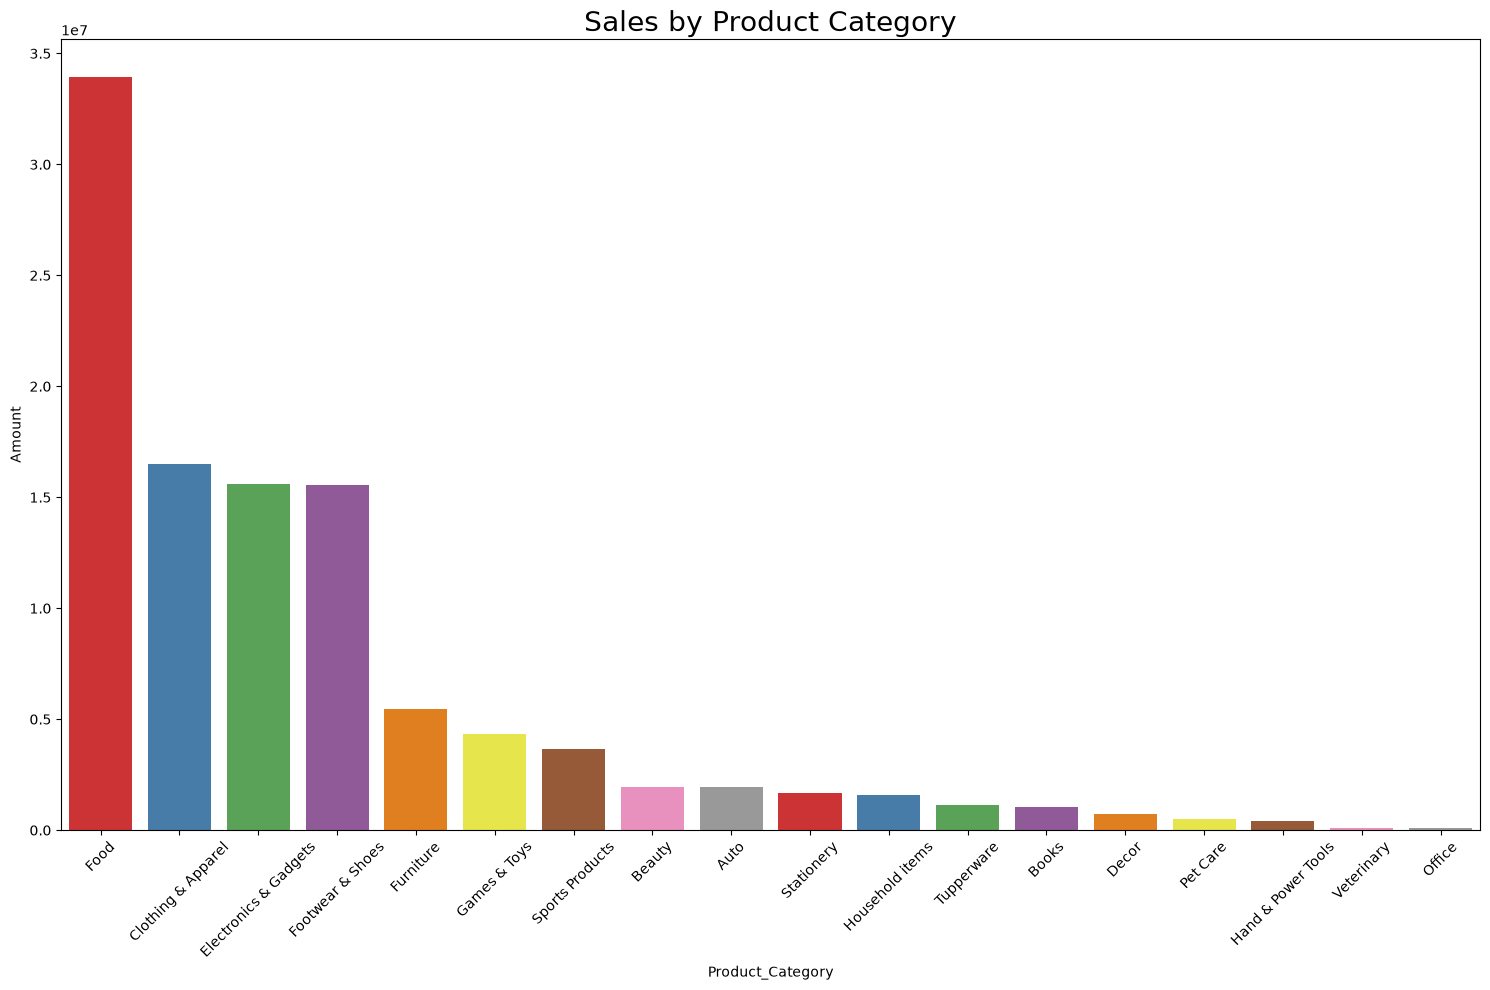

In [23]:
# Product_Category Wise analysis
fig,ax=plt.subplots(figsize=(15,10))
sales_prod=df.groupby('Product_Category',as_index=False)['Amount'].sum().sort_values(
    by='Amount',ascending=False)
sns.barplot(x='Product_Category',y='Amount',data=sales_prod,hue='Product_Category',palette='Set1',ax=ax)
ax.set_title('Sales by Product Category',fontsize=20)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Product-category analysis — practice stage 2

Same aggregation, different `coolwarm` palette and rotated labels. This was a styling experiment, not a new analysis.

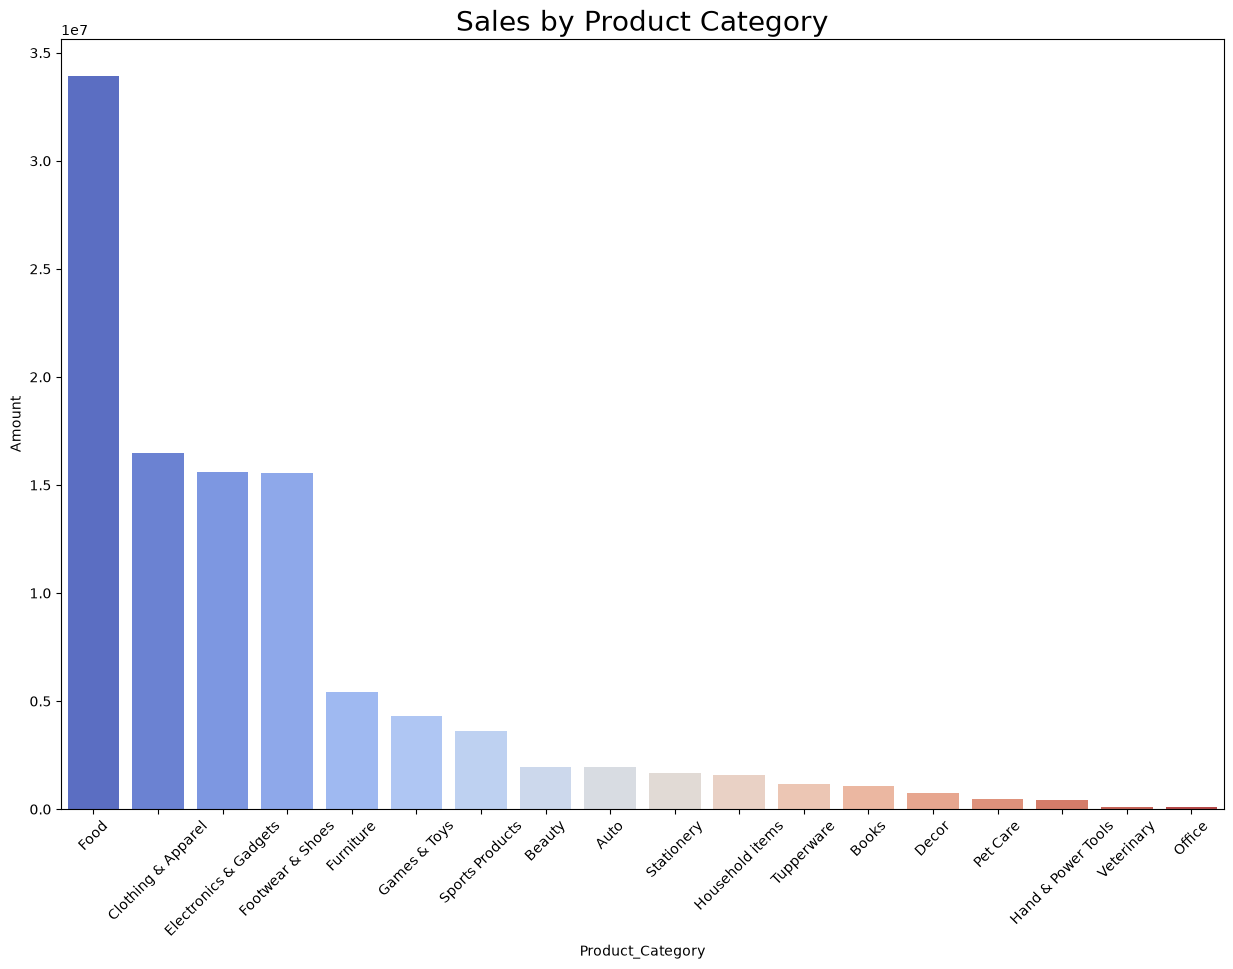

In [24]:
# Product_Category Wise analysis
fig,ax=plt.subplots(figsize=(15,10))
sales_prod=df.groupby('Product_Category',as_index=False)['Amount'].sum().sort_values(
    by='Amount',ascending=False)
sns.barplot(x='Product_Category',y='Amount',data=sales_prod,hue='Product_Category',palette='coolwarm',ax=ax)
ax.set_title('Sales by Product Category',fontsize=20)
plt.xticks(rotation=45)
plt.show()


### Product-category analysis — practice stage 3 (selected presentation version)

This returns to the original `Set1` palette and retains the rotated labels. Compare the three stages to understand that changing the palette does **not** change the underlying sales totals.

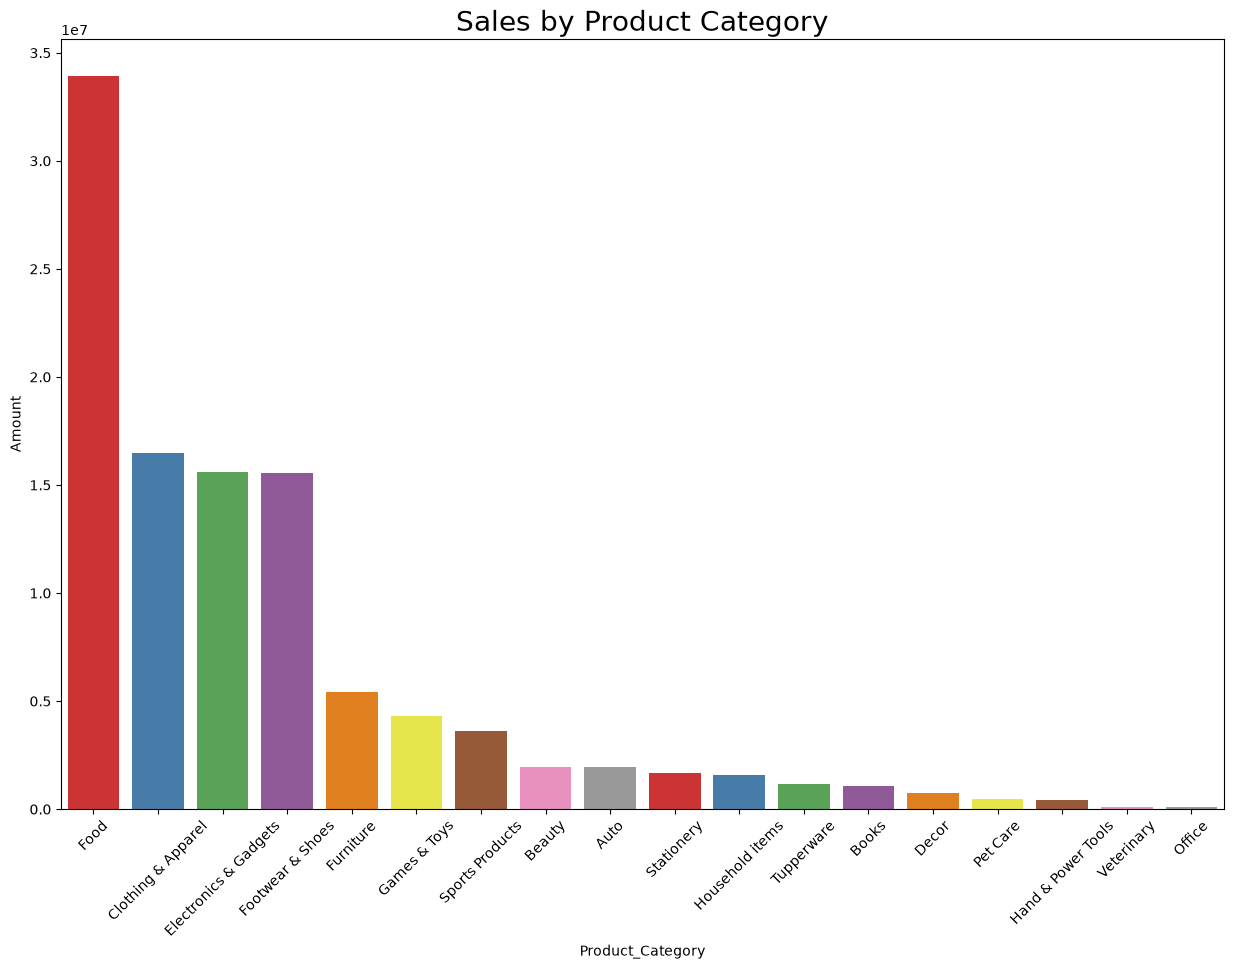

In [25]:
# Product_Category Wise analysis
fig,ax=plt.subplots(figsize=(15,10))
sales_prod=df.groupby('Product_Category',as_index=False)['Amount'].sum().sort_values(
    by='Amount',ascending=False)
sns.barplot(x='Product_Category',y='Amount',data=sales_prod,hue='Product_Category',palette='Set1',ax=ax)
ax.set_title('Sales by Product Category',fontsize=20)
plt.xticks(rotation=45)
plt.show()


**Original finding:** **Food** had the largest total recorded amount among product categories in the original analysis. This is a total-value comparison, not necessarily the highest number of orders.

## 16. Marital-status analysis — practice stage 1

**Question:** How does total recorded spending compare across marital-status categories?

The original mapping converted `0` to `single` and `1` to `Married`. The first bar plot sorts categories by total `Amount`.

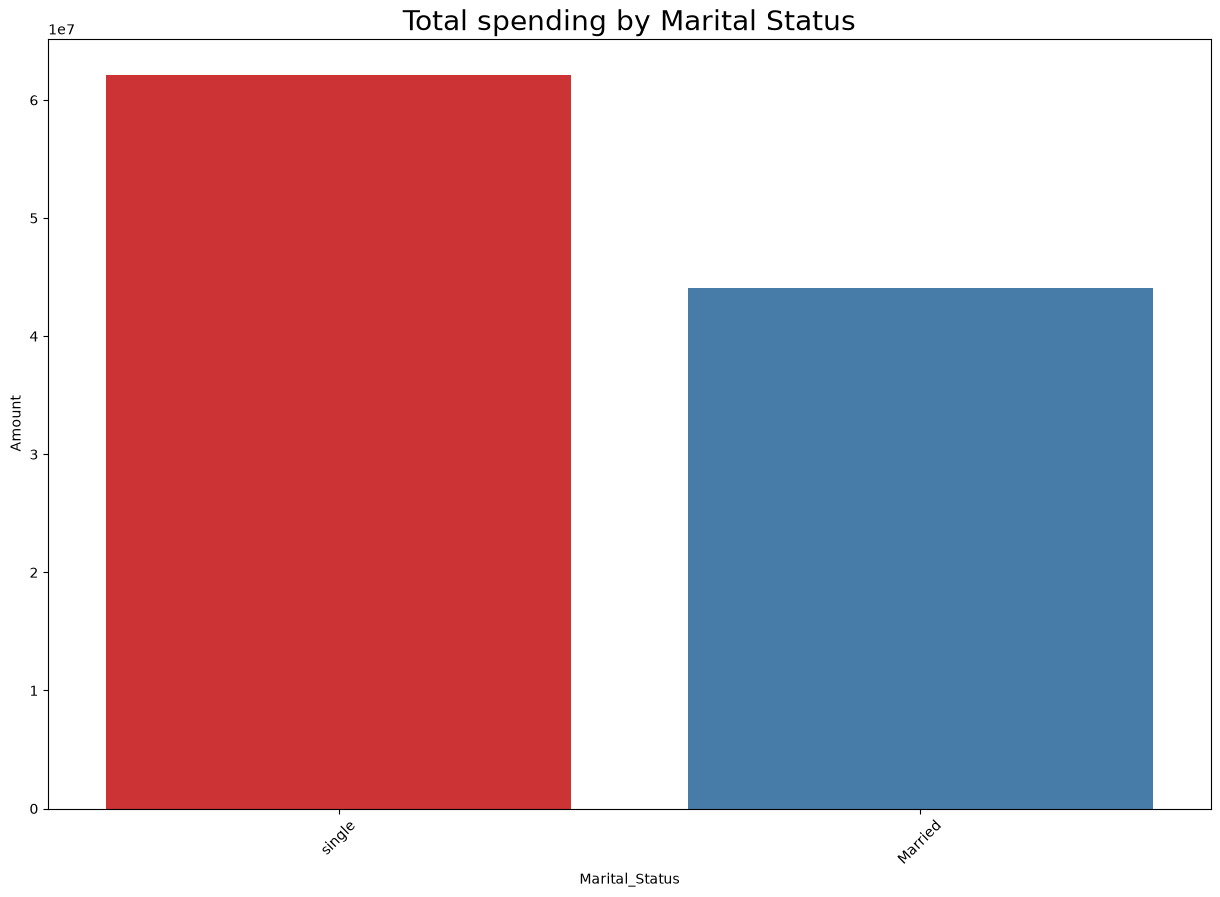

In [26]:
# Marital Status Wise analysis 
fig,ax=plt.subplots(figsize=(15,10))
marital_status=df.groupby('Marital_Status',as_index=False)['Amount'].sum().sort_values(
    by='Amount',ascending=False)
sns.barplot(x='Marital_Status',y='Amount',data=marital_status,hue='Marital_Status',palette='Set1',ax=ax)
ax.set_title('Total spending by Marital Status',fontsize=20)
plt.xticks(rotation=45)
plt.show()

### Marital-status analysis — practice stage 2

This version performs the same grouping without sorting. It helps show the difference between the order of categories and the underlying totals.

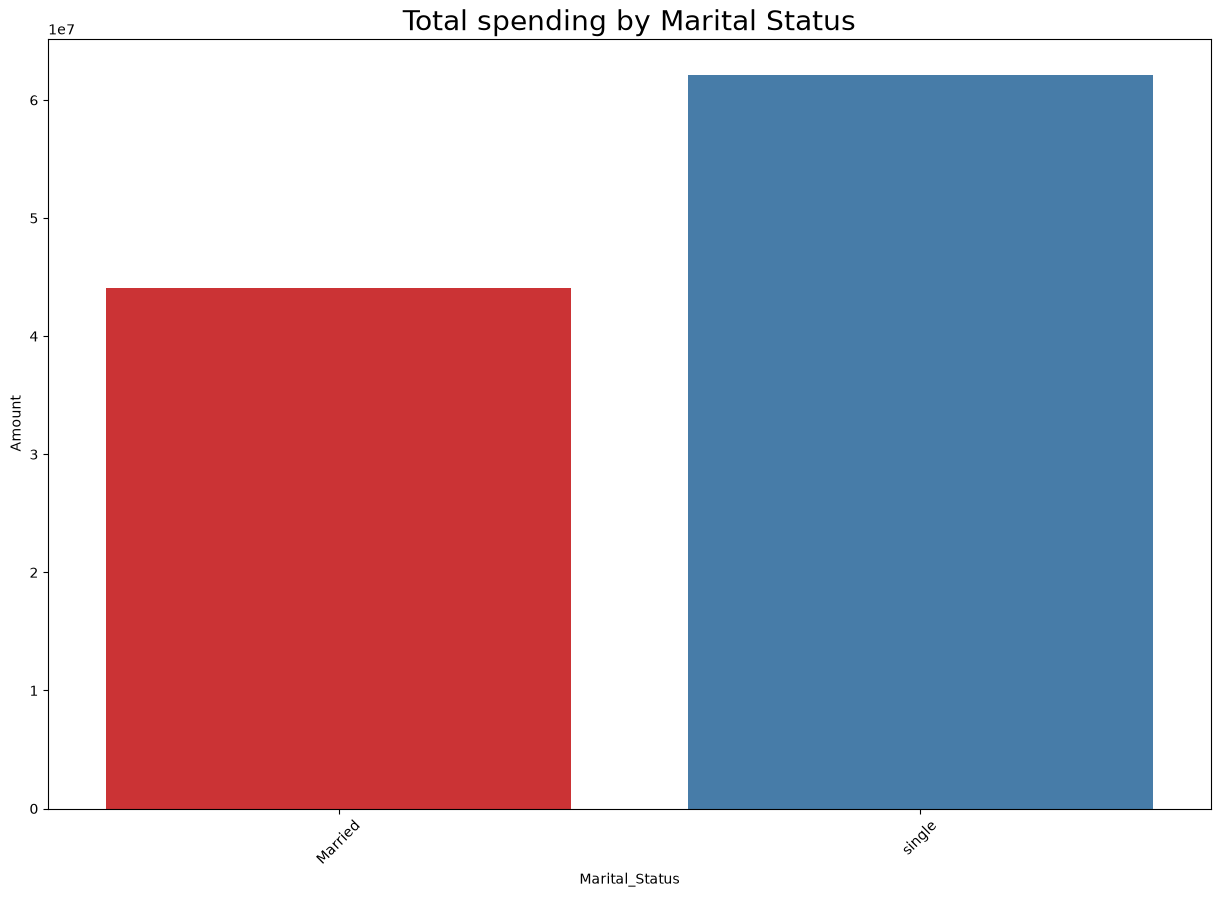

In [27]:
# Marital Status Wise analysis 
fig,ax=plt.subplots(figsize=(15,10))
marital_status=df.groupby('Marital_Status',as_index=False)['Amount'].sum()
sns.barplot(x='Marital_Status',y='Amount',data=marital_status,hue='Marital_Status',palette='Set1',ax=ax)
ax.set_title('Total spending by Marital Status',fontsize=20)
plt.xticks(rotation=45)
plt.show()

### Marital-status analysis — practice stage 3: add bar values

This stage uses `ax.bar_label()` and plain y-axis formatting. The original x-axis was accidentally labelled **Gender**; it is corrected to **Marital Status**.

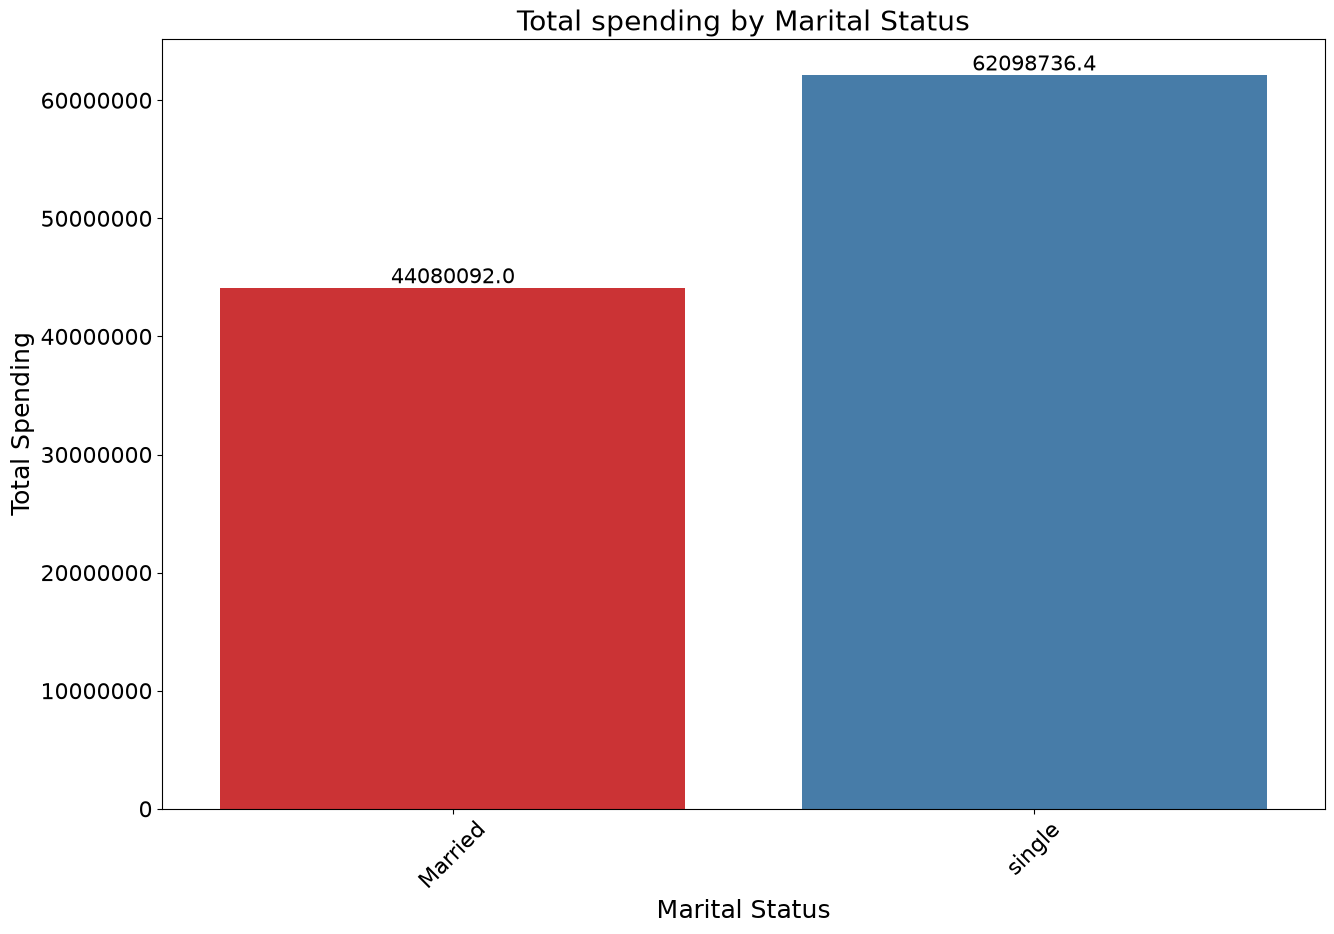

In [28]:
# Marital Status Wise analysis 
fig,ax=plt.subplots(figsize=(15,10))
ax.tick_params(axis='both',labelsize=16)
ax.set_xlabel('Marital Status',fontsize=18)
ax.set_ylabel('Total Spending',fontsize=18)
marital_status=df.groupby('Marital_Status',as_index=False)['Amount'].sum()
sns.barplot(x='Marital_Status',y='Amount',data=marital_status,hue='Marital_Status',palette='Set1',ax=ax)
for container in ax.containers:
    ax.bar_label(container,fontsize=15,label_type='edge',fmt='%.1f')
    #fmt='%d' ----> integer value ko show karega
ax.ticklabel_format(axis='y',style='plain')  # 'y' axis ko plain format me show karta hai   
ax.set_title('Total spending by Marital Status',fontsize=20)
plt.xticks(rotation=45)
plt.show()

### Marital-status analysis — final pastel chart

This final variation changes the palette to `pastel` while keeping numeric labels. As above, the x-axis label is corrected to **Marital Status**.

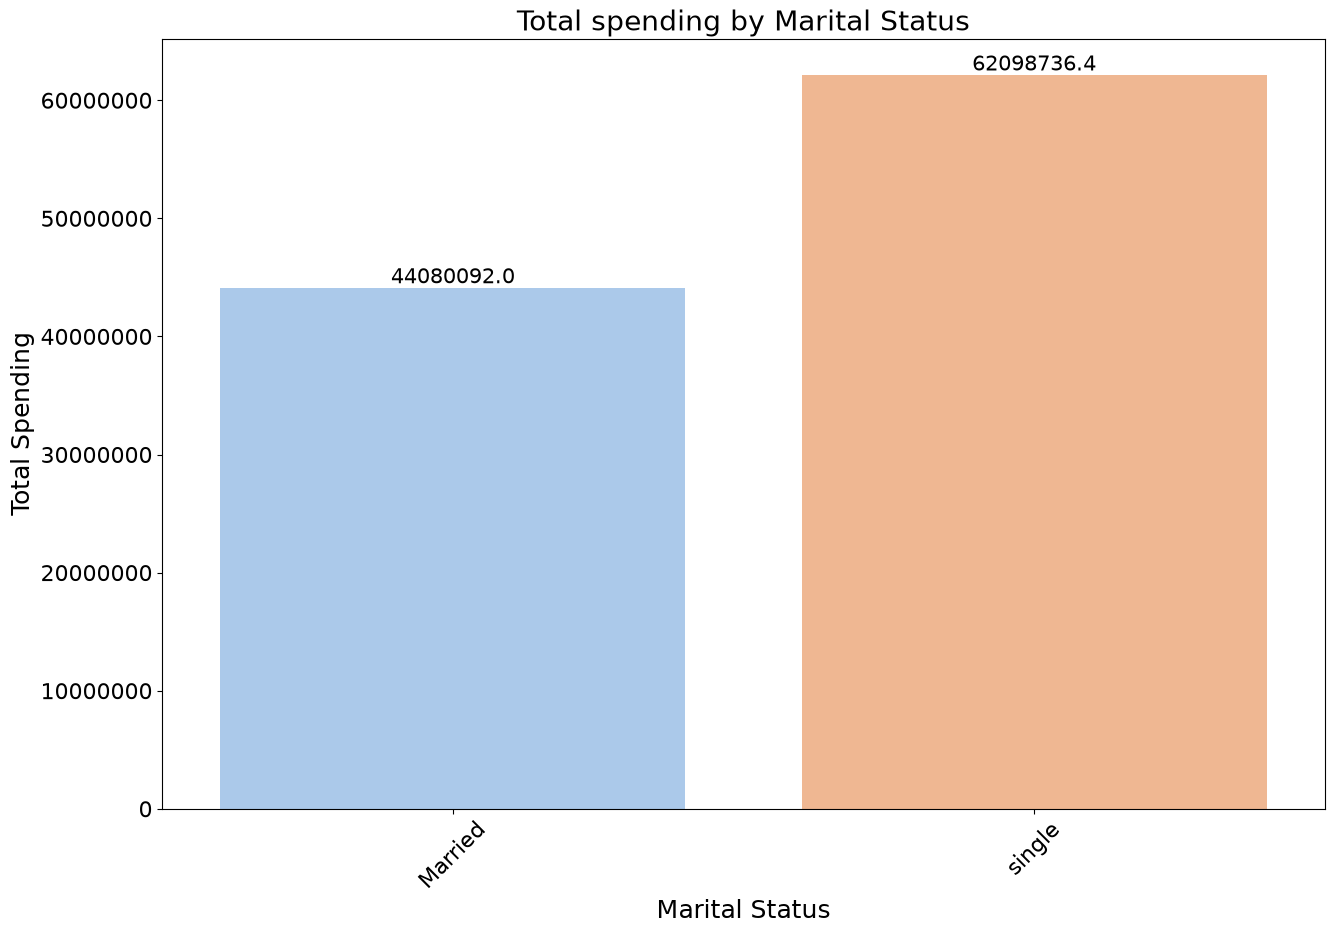

In [29]:
# Marital Status Wise analysis 
fig,ax=plt.subplots(figsize=(15,10))
ax.tick_params(axis='both',labelsize=16)
ax.set_xlabel('Marital Status',fontsize=18)
ax.set_ylabel('Total Spending',fontsize=18)
marital_status=df.groupby('Marital_Status',as_index=False)['Amount'].sum()
sns.barplot(x='Marital_Status',y='Amount',data=marital_status,hue='Marital_Status',palette='pastel',ax=ax)
for container in ax.containers:
    ax.bar_label(container,fontsize=15,label_type='edge',fmt='%.1f')
    #fmt='%d' ----> integer value ko show karega
ax.ticklabel_format(axis='y',style='plain')  # 'y' axis ko plain format me show karta hai   
ax.set_title('Total spending by Marital Status',fontsize=20)
plt.xticks(rotation=45)
plt.show()

**Interpretation:** The bars compare the total recorded amount for **single** and **Married** categories. The original notebook did not include a written conclusion for this comparison, so the result should be read from the rerun chart rather than assumed.

## 17. Verify the main findings from the cleaned dataset

The following code prints the **top group and its total amount** for each analysis. This gives a numerical check of the conclusions described above without exposing individual customer names or IDs. It uses the same `groupby()` and `sum()` approach already practised throughout the notebook.

In [30]:
for column in ['Gender', 'Age Group', 'State', 'Occupation', 'Product_Category', 'Marital_Status']:
    totals = df.groupby(column)['Amount'].sum().sort_values(ascending=False)
    if not totals.empty:
        print(column, '->', totals.index[0], '| Total Amount:', round(totals.iloc[0], 2))

Gender -> Female | Total Amount: 74307682.43
Age Group -> 26-35 | Total Amount: 42581768.94
State -> Uttar Pradesh | Total Amount: 19346055.0
Occupation -> IT Sector | Total Amount: 14741862.0
Product_Category -> Food | Total Amount: 33933883.5
Marital_Status -> single | Total Amount: 62098736.44


## 18. Summary and conclusions

The **original notebook** reported these patterns:

1. **Gender:** Female-labelled records accounted for the larger share of total recorded spending.
2. **Age group:** Ages **26–35** had the highest total recorded amount.
3. **State:** **Uttar Pradesh** ranked highest in total recorded spending.
4. **Occupation:** **IT Sector** ranked highest by total recorded amount.
5. **Product category:** **Food** ranked highest by total recorded amount.
6. **Marital status:** Compare the two totals in the chart; no unverified winner is asserted here.

**Important:** These are observations from the original project, not independently verified conclusions from a fresh CSV run. Use the preceding verification cell to check them against your final cleaned dataset. All comparisons concern **total recorded spending**, not average spend per customer or causal effects.

### What I learned
- Inspecting dataset shape and missing values with Pandas.
- Removing irrelevant columns, missing-amount records, and exact duplicates.
- Mapping coded categories into readable labels.
- Using `groupby()` with `sum()` to compare categories.
- Building count plots, pie charts, and bar plots, then improving labels and styling.

### Limitations and next steps
- The original dataset's redistribution permission has not been established; publish only permitted data.
- The analysis is descriptive, with no statistical significance testing or causal claims.
- Comparing **totals** can be affected by different numbers of customers/records in each group.
- A future extension could add per-customer averages, order-level checks, Excel summaries, SQL queries, or a Power BI dashboard **after they are actually implemented**.

### Reproducibility and privacy
The notebook includes executed analysis results, visualizations, and aggregated sales findings. Customer names and individual customer IDs are excluded from displayed data previews. The original source CSV is not included in this repository because its redistribution permission has not been independently confirmed.